# Notebook 59 — Diffusion intuition and rectified flow

Diffusion-style models learn to transform a simple noise distribution into a data distribution. Full modern diffusion systems contain many engineering and mathematical details, so this notebook keeps the setting deliberately small: two-dimensional points with eight visible modes.

We first inspect the forward diffusion process, where clean data is gradually corrupted with Gaussian noise. We then train a small **rectified-flow** model, which learns a velocity field that transports noise toward data. This is not a production image generator; it is a visual experiment for understanding the central ideas.

For a conceptual overview, see [Diffusion intuition and rectified flow](../notes/14-generative-models/diffusion-and-rectified-flow.md).

## Learning goals

- distinguish forward noising from learned generation;
- use a cumulative noise schedule and understand its shapes;
- recover a clean estimate from a noisy sample and a noise estimate;
- construct rectified-flow interpolation pairs and target velocities;
- condition a velocity network on continuous time;
- generate samples by integrating the learned velocity field with Euler steps;
- investigate how the number of sampling steps affects the result.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# CPU is sufficient for this small experiment and gives predictable runtime.
DEVICE = torch.device("cpu")
print("device:", DEVICE)

device: cpu


## 1. Data and noise distributions

We reuse the eight-mode distribution from the [GAN notebook](./58_gan_intuition_and_adversarial_training.ipynb). Clean samples $x_0$ lie near eight cluster centers. Noise samples $\epsilon$ come from a standard two-dimensional Gaussian distribution:

$$
x_0 \sim p_{data},
\qquad
\epsilon \sim \mathcal{N}(0,I).
$$

The subscript zero in $x_0$ denotes clean data at the beginning of the forward noising process. It is not a batch index.

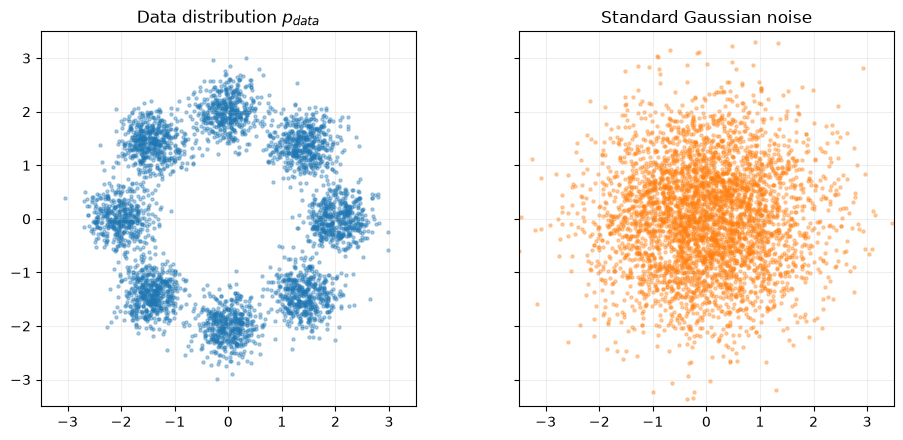

In [5]:
NUMBER_MODES = 8
DATA_RADIUS = 2.0
CLUSTER_STD = 0.3
DATA_DIM = 2

angles = torch.linspace(0, 2 * torch.pi, NUMBER_MODES + 1)[:-1]
MODE_CENTERS = DATA_RADIUS * torch.stack(
    (torch.cos(angles), torch.sin(angles)),
    dim=1,
)


def sample_real_data(batch_size, *, device=DEVICE):
    mode_indices = torch.randint(0, NUMBER_MODES, (batch_size,), device=device)
    centers = MODE_CENTERS.to(device)
    return centers[mode_indices] + CLUSTER_STD * torch.randn(
        batch_size, DATA_DIM, device=device
    )


def sample_noise(batch_size, *, device=DEVICE):
    return torch.randn(batch_size, DATA_DIM, device=device)


real_examples = sample_real_data(4000)
noise_examples = sample_noise(4000)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
axes[0].scatter(*real_examples.T, s=5, alpha=0.35)
axes[0].set_title("Data distribution $p_{data}$")
axes[1].scatter(*noise_examples.T, s=5, alpha=0.35, color="tab:orange")
axes[1].set_title("Standard Gaussian noise")
for axis in axes:
    axis.set_aspect("equal")
    axis.set_xlim(-3.5, 3.5)
    axis.set_ylim(-3.5, 3.5)
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 2. Forward diffusion: gradually corrupting data

A variance-preserving forward process combines a clean sample with Gaussian noise:

$$
x_t=\sqrt{\bar{\alpha}_t}x_0+\sqrt{1-\bar{\alpha}_t}\epsilon.
$$

Here:

- $x_0$ is a clean sample;
- $x_t$ is its noisy version at discrete step $t$;
- $\epsilon$ is freshly sampled Gaussian noise with the same shape as $x_0$;
- $\alpha_t=1-\beta_t$ retains a little signal at one step;
- $\bar{\alpha}_t=\prod_{s=0}^{t}\alpha_s$ is the cumulative retained-signal fraction.

Early steps have $\bar{\alpha}_t$ near one, so $x_t$ mostly contains data. Later steps have a smaller value, so noise dominates. The formula directly samples any $x_t$ without constructing all earlier states.

### Exercise 1 — Implement direct forward noising

Each example may use a different time index. Gather the corresponding cumulative coefficient and reshape it to `(N, 1)` so it broadcasts across the two coordinates.

In [7]:
NUMBER_DIFFUSION_STEPS = 100
betas = torch.linspace(5e-4, 0.08, NUMBER_DIFFUSION_STEPS, device=DEVICE)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)


def diffuse(clean_samples, time_indices, noise=None):
    if noise is None:
        noise = torch.randn_like(clean_samples)

    # select alpha_bars for this batch and reshape to (N, 1).
    alpha_bar_t = alpha_bars[time_indices].reshape(-1, 1)
    # combine retained clean signal with Gaussian noise.
    noisy_samples = (alpha_bar_t.sqrt() * clean_samples) + ((1.0 - alpha_bar_t).sqrt() * noise)
    return noisy_samples, noise


test_clean = torch.tensor([[1.0, 2.0], [-1.0, 0.5]])
test_times = torch.tensor([0, NUMBER_DIFFUSION_STEPS - 1])
test_noise = torch.tensor([[0.5, -0.5], [1.0, -1.0]])
test_noisy, returned_noise = diffuse(test_clean, test_times, test_noise)
expected_coefficients = alpha_bars[test_times].reshape(-1, 1)
expected_noisy = (
    expected_coefficients.sqrt() * test_clean
    + (1.0 - expected_coefficients).sqrt() * test_noise
)
assert test_noisy.shape == test_clean.shape
torch.testing.assert_close(test_noisy, expected_noisy)
torch.testing.assert_close(returned_noise, test_noise)

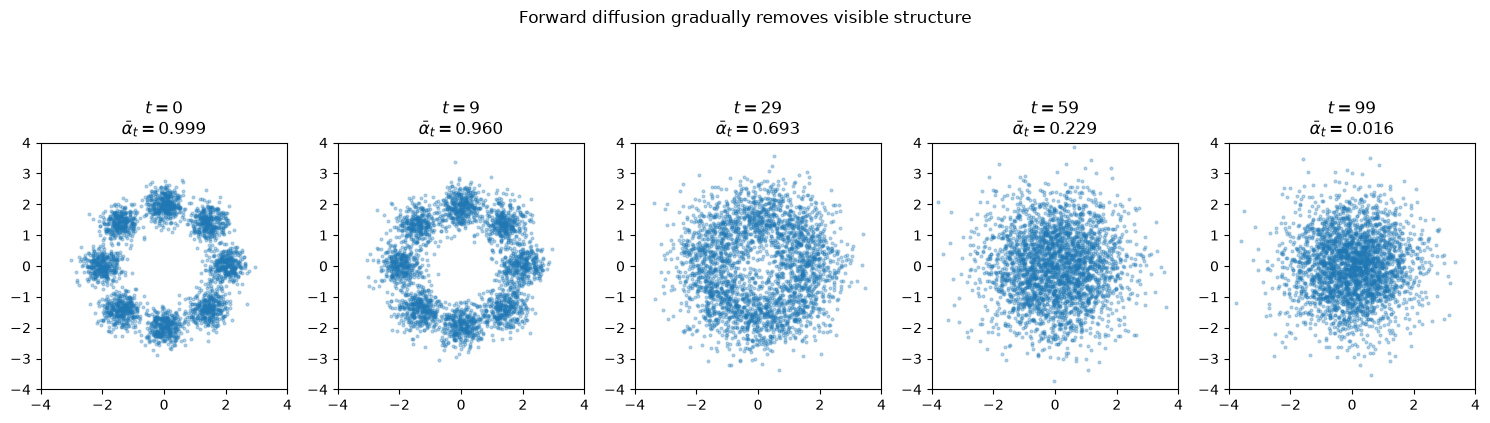

In [13]:
visualization_steps = [0, 9, 29, 59, 99]
clean_reference = sample_real_data(3000)
fixed_noise = torch.randn_like(clean_reference)

fig, axes = plt.subplots(1, len(visualization_steps), figsize=(15, 5))
for axis, step in zip(axes, visualization_steps):
    times = torch.full((len(clean_reference),), step, dtype=torch.long)
    noisy, _ = diffuse(clean_reference, times, fixed_noise)
    axis.scatter(*noisy.T, s=4, alpha=0.3)
    axis.set_title(
        f"$t={step}$\n"
        + rf"$\bar{{\alpha}}_t={alpha_bars[step]:.3f}$"
    )
    axis.set_aspect("equal")
    axis.set_xlim(-4, 4)
    axis.set_ylim(-4, 4)
plt.suptitle("Forward diffusion gradually removes visible structure")
plt.tight_layout()
plt.show()

## 3. What a diffusion model predicts

A common diffusion network receives a noisy sample $x_t$ and its time $t$, then predicts the noise that was added:

$$
\hat{\epsilon}=\epsilon_\theta(x_t,t).
$$

If the predicted noise is accurate, rearranging the forward equation gives an estimate of the original clean sample:

$$
\hat{x}_0=\frac{x_t-\sqrt{1-\bar{\alpha}_t}\hat{\epsilon}}
{\sqrt{\bar{\alpha}_t}}.
$$

This algebraic recovery demonstrates what a noise prediction tells us. Actual diffusion sampling repeatedly applies a scheduler-specific reverse update; it does not normally jump from pure noise to a final sample with this formula alone.

### Exercise 2 — Recover clean samples when the noise is known

In [16]:
def reconstruct_clean(noisy_samples, predicted_noise, alpha_bar_t):
    # rearrange the forward-diffusion equation to estimate x_0.
    return (noisy_samples - (1.0 - alpha_bar_t).sqrt() * predicted_noise) / alpha_bar_t.sqrt()


clean = sample_real_data(64)
times = torch.randint(0, NUMBER_DIFFUSION_STEPS, (64,))
noisy, exact_noise = diffuse(clean, times)
coefficients = alpha_bars[times].reshape(-1, 1)
recovered = reconstruct_clean(noisy, exact_noise, coefficients)
assert recovered.shape == clean.shape
torch.testing.assert_close(recovered, clean, atol=1e-5, rtol=1e-5)

## 4. Rectified flow: learn a direction from noise to data

Rectified flow uses a particularly direct training construction. Pair a noise point $x_{noise}$ with a data point $x_{data}$ and choose continuous time $t\in[0,1]$. A point on the straight path between them is

$$
x_t=(1-t)x_{noise}+t x_{data}.
$$

The velocity along this particular straight path is constant:

$$
v_{target}=x_{data}-x_{noise}.
$$

The model sees only $(x_t,t)$, not the paired endpoints. Across many random pairs it learns the average useful direction $v_\theta(x_t,t)$. At generation time we begin with noise at $t=0$ and repeatedly follow the learned field until $t=1$.

This forward direction is a convention used in this notebook. Some sources define time in the opposite direction, so always check which endpoint corresponds to $t=0$.

### Exercise 3 — Construct a batch of flow-training pairs

Keep `times` shaped `(N, 1)`. That shape broadcasts one time value over the two coordinates of each sample without mixing examples.

In [ ]:
def sample_flow_pairs(batch_size, *, device=DEVICE):
    noise = sample_noise(batch_size, device=device)
    data = sample_real_data(batch_size, device=device)
    # sample one continuous time in [0, 1] per example with shape (N, 1).
    times = torch.rand(batch_size, 1, device=device)
    # interpolate from noise at t=0 to data at t=1.
    interpolated = noise + times * (data - noise)
    # calculate the straight-path target velocity.
    target_velocity = data - noise
    return interpolated, times, target_velocity, noise, data


interpolated, times, target_velocity, noise, data = sample_flow_pairs(128)
assert interpolated.shape == target_velocity.shape == noise.shape == data.shape == (128, 2)
assert times.shape == (128, 1)
assert torch.all((times >= 0.0) & (times <= 1.0))
torch.testing.assert_close(interpolated, noise + times * target_velocity)

The plot below uses fixed endpoint pairs and changes only time. Individual points travel on straight lines, while the distribution gradually changes from Gaussian noise into the eight-mode data distribution.

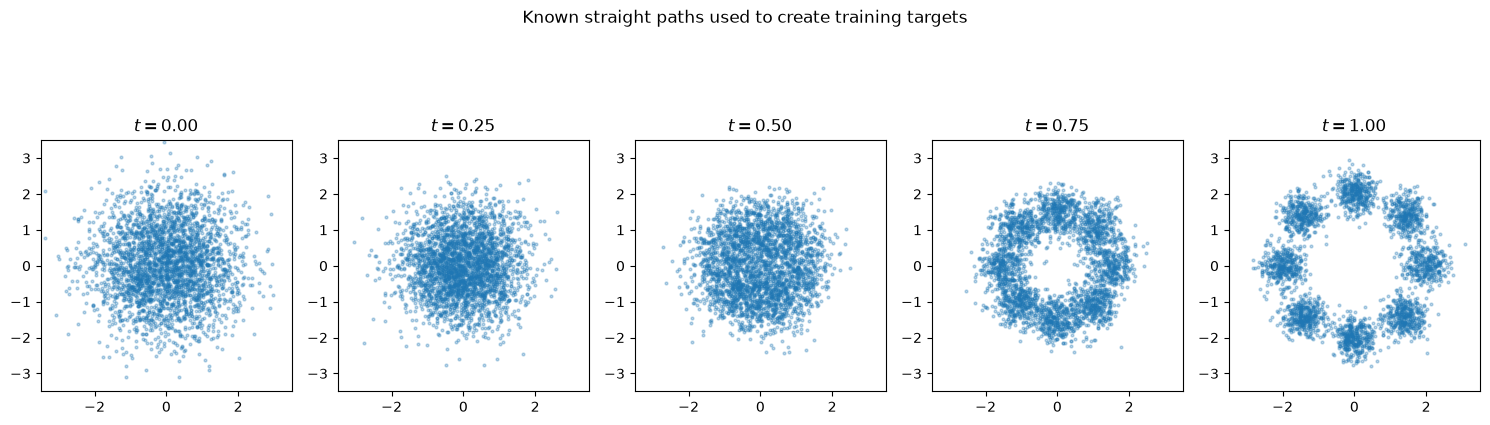

In [19]:
torch.manual_seed(SEED)
flow_noise = sample_noise(3000)
flow_data = sample_real_data(3000)
flow_times = [0.0, 0.25, 0.5, 0.75, 1.0]

fig, axes = plt.subplots(1, len(flow_times), figsize=(15, 5))
for axis, time in zip(axes, flow_times):
    points = (1.0 - time) * flow_noise + time * flow_data
    axis.scatter(*points.T, s=4, alpha=0.3)
    axis.set_title(f"$t={time:.2f}$")
    axis.set_aspect("equal")
    axis.set_xlim(-3.5, 3.5)
    axis.set_ylim(-3.5, 3.5)
plt.suptitle("Known straight paths used to create training targets")
plt.tight_layout()
plt.show()

## 5. A time-conditioned velocity network

The required direction depends on both position and time. The same coordinate can require a different velocity early and late in the transformation, so the network receives three values per example:

```text
(x coordinate, y coordinate, time) -> MLP -> (x velocity, y velocity)
```

Large image models use richer time embeddings, usually sinusoidal features followed by learned projections. Concatenating the scalar time is enough for this toy experiment.

### Exercise 4 — Combine positions and times in `forward`

In [20]:
class VelocityMLP(nn.Module):
    def __init__(self, hidden_dim=128):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(DATA_DIM + 1, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, DATA_DIM),
        )

    def forward(self, positions, times):
        # concatenate each 2D position with its time, then predict velocity.
        model_inputs = torch.cat((positions, times), dim=1)
        return self.network(model_inputs)


shape_model = VelocityMLP(hidden_dim=32)
shape_positions = torch.randn(7, 2)
shape_times = torch.rand(7, 1)
shape_velocities = shape_model(shape_positions, shape_times)
assert shape_velocities.shape == shape_positions.shape

## 6. Train the velocity field

Training is ordinary supervised regression once the artificial pairs are constructed. We minimize mean squared error between the predicted and target velocities:

$$
\mathcal{L}_{flow}=\frac{1}{N}\sum_{n=1}^{N}
\left\lVert
v_\theta(x_t^{(n)},t^{(n)})-v_{target}^{(n)}
\right\rVert_2^2.
$$

The target is available because we selected both endpoints ourselves. The model is not asked to recover which exact data point was paired with a position; it learns a velocity that works on average across the training distribution.

### Exercise 5 — Implement the flow loss

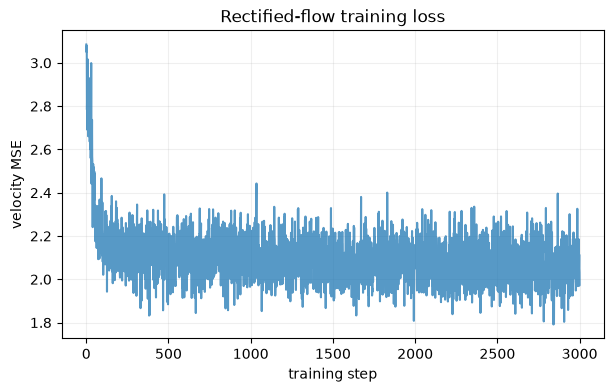

In [24]:
def rectified_flow_loss(model, batch_size):
    # sample a training batch and predict its velocities.
    interpolated, times, target_velocity, _, _ = sample_flow_pairs(batch_size)
    predicted_velocity = model(interpolated, times)
    # return mean squared error against the target velocity.
    return torch.mean((predicted_velocity - target_velocity) ** 2)


def train_rectified_flow(steps=3000, batch_size=512, learning_rate=2e-3, seed=SEED):
    torch.manual_seed(seed)
    model = VelocityMLP().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []

    model.train()
    for _ in range(steps):
        optimizer.zero_grad()
        loss = rectified_flow_loss(model, batch_size)
        loss.backward()
        optimizer.step()
        history.append(loss.item())
    return model, history


flow_model, flow_history = train_rectified_flow()
assert len(flow_history) == 3000
assert np.isfinite(flow_history).all()

plt.figure(figsize=(7, 4))
plt.plot(flow_history, alpha=0.75)
plt.xlabel("training step")
plt.ylabel("velocity MSE")
plt.title("Rectified-flow training loss")
plt.grid(alpha=0.2)
plt.show()

## 7. Generate by following the learned field

The trained model defines the differential equation

$$
\frac{dx}{dt}=v_\theta(x,t).
$$

Starting from Gaussian noise, we approximate its solution with Euler updates. For step width $\Delta t=1/K$,

$$
x_{k+1}=x_k+\Delta t\,v_\theta(x_k,t_k).
$$

This is numerical integration, not another training update: model parameters remain fixed while sample positions move. A smaller step width usually follows the learned field more accurately but requires more network evaluations.

### Exercise 6 — Implement Euler sampling

In [26]:
@torch.no_grad()
def sample_rectified_flow(model, initial_noise, number_steps, snapshot_indices=()):
    model.eval()
    positions = initial_noise.clone()
    step_width = 1.0 / number_steps
    snapshots = {0: positions.detach().cpu().clone()}

    for step in range(number_steps):
        # create one time value per sample with shape (N, 1).
        times = torch.full((len(positions), 1), step * step_width, device=DEVICE)
        # predict velocity and take one Euler step.
        positions = positions + step_width * model(positions, times)
        completed_step = step + 1
        if completed_step in snapshot_indices or completed_step == number_steps:
            snapshots[completed_step] = positions.detach().cpu().clone()

    return positions.detach().cpu(), snapshots


class ZeroVelocity(nn.Module):
    def forward(self, positions, times):
        return torch.zeros_like(positions)


sampler_test_noise = torch.randn(12, 2)
unchanged, _ = sample_rectified_flow(ZeroVelocity(), sampler_test_noise, 5)
torch.testing.assert_close(unchanged, sampler_test_noise)

torch.manual_seed(SEED + 1)
initial_noise = sample_noise(4000)
generated_points, generation_snapshots = sample_rectified_flow(
    flow_model,
    initial_noise,
    number_steps=100,
    snapshot_indices=(25, 50, 75),
)
assert generated_points.shape == initial_noise.shape
assert set(generation_snapshots) == {0, 25, 50, 75, 100}

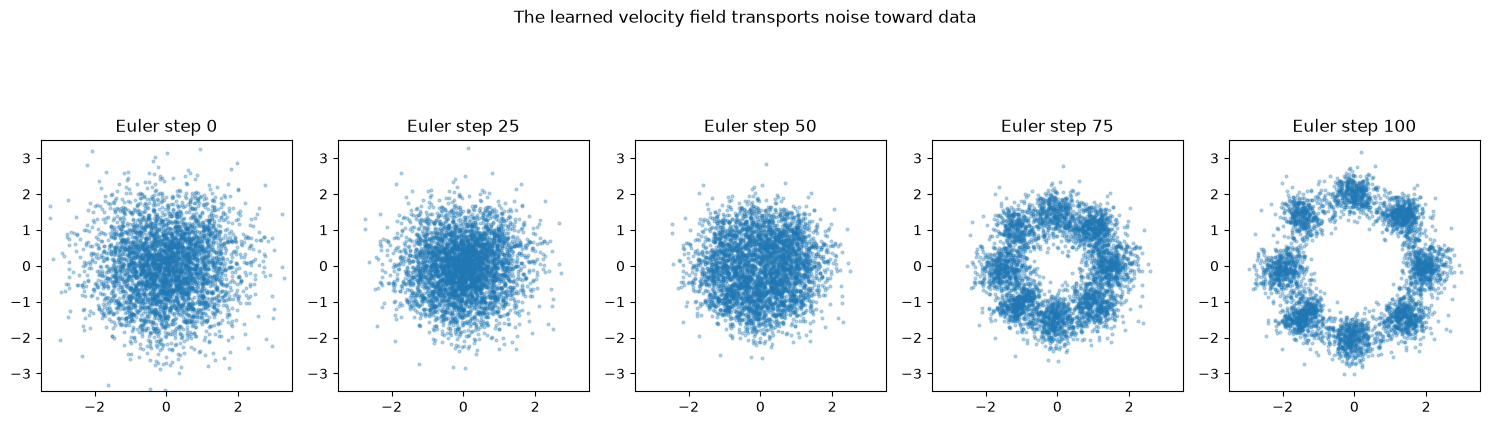

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


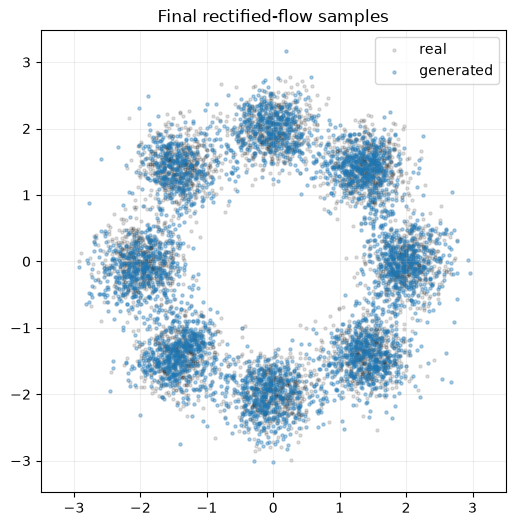

In [28]:
fig, axes = plt.subplots(1, len(generation_snapshots), figsize=(15, 5))
for axis, (step, points) in zip(axes, generation_snapshots.items()):
    axis.scatter(*points.T, s=4, alpha=0.3)
    axis.set_title(f"Euler step {step}")
    axis.set_aspect("equal")
    axis.set_xlim(-3.5, 3.5)
    axis.set_ylim(-3.5, 3.5)
plt.suptitle("The learned velocity field transports noise toward data")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 6))
plt.scatter(*sample_real_data(4000).T, s=5, alpha=0.12, color="black", label="real")
plt.scatter(*generated_points.T, s=5, alpha=0.35, color="tab:blue", label="generated")
plt.axis("equal")
plt.xlim(-3.5, 3.5)
plt.ylim(-3.5, 3.5)
plt.title("Final rectified-flow samples")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 8. Sampling accuracy versus computation

The same trained model can be integrated with different numbers of Euler steps. Fewer steps are faster, but each update covers a larger time interval and introduces more numerical error. More steps are not guaranteed to repair an inaccurate learned velocity field; they only integrate the available field more finely.

We again use nearest-mode statistics because the toy distribution has known centers. This diagnostic is not a general metric for generated images.

### Exercise 7 — Compare 5, 20, and 100 sampling steps

Run the cell and interpret both coverage and mean nearest-mode distance. Do not assume the result must improve monotonically in this small stochastic experiment.

  2 steps: 8/8 modes, mean nearest-mode distance=0.814
  5 steps: 8/8 modes, mean nearest-mode distance=0.440
 20 steps: 8/8 modes, mean nearest-mode distance=0.396
100 steps: 8/8 modes, mean nearest-mode distance=0.394


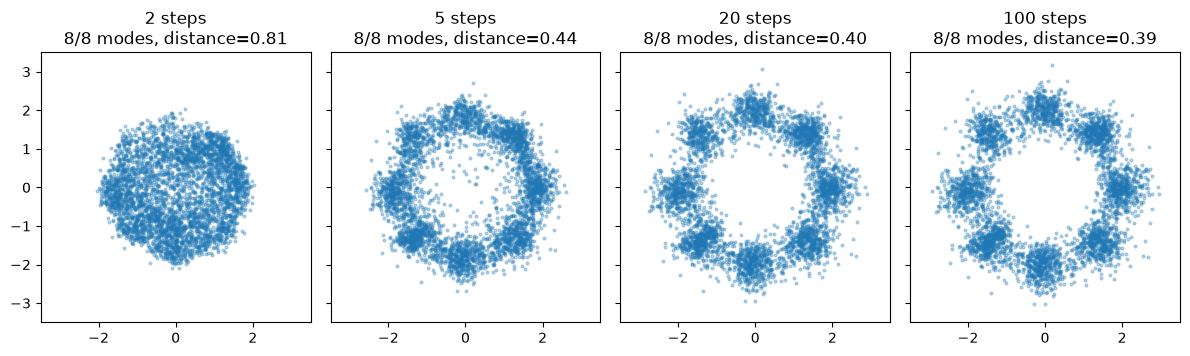

In [32]:
def mode_statistics(points, centers=MODE_CENTERS, minimum_fraction=0.02):
    points = points.detach().cpu()
    centers = centers.detach().cpu()
    distances = torch.cdist(points, centers)
    assignments = distances.argmin(dim=1)
    counts = torch.bincount(assignments, minlength=len(centers))
    fractions = counts.float() / len(points)
    covered = int((fractions >= minimum_fraction).sum().item())
    mean_nearest_distance = distances.min(dim=1).values.mean().item()
    return fractions, covered, mean_nearest_distance


step_counts = [2, 5, 20, 100]
step_results = {}
for number_steps in step_counts:
    points, _ = sample_rectified_flow(flow_model, initial_noise, number_steps)
    fractions, covered, distance = mode_statistics(points)
    step_results[number_steps] = (points, fractions, covered, distance)
    print(
        f"{number_steps:>3} steps: {covered}/{NUMBER_MODES} modes, "
        f"mean nearest-mode distance={distance:.3f}"
    )

fig, axes = plt.subplots(1, len(step_counts), figsize=(12, 4), sharex=True, sharey=True)
for axis, number_steps in zip(axes, step_counts):
    points, _, covered, distance = step_results[number_steps]
    axis.scatter(*points.T, s=4, alpha=0.3)
    axis.set_title(f"{number_steps} steps\n{covered}/8 modes, distance={distance:.2f}")
    axis.set_aspect("equal")
    axis.set_xlim(-3.5, 3.5)
    axis.set_ylim(-3.5, 3.5)
plt.tight_layout()
plt.show()

## 9. Training paths versus generated paths

Each artificial training pair defines a straight target path. The learned model does not remember those pairs, however. Its velocity depends on the current position and time, and numerical sampling repeatedly reevaluates that velocity. A generated trajectory can therefore curve as it moves through the learned average field.

### Exercise 8 — Visualize several generated trajectories

Use every integration step as a snapshot, stack the positions of the first 20 samples, and draw one path per sample.

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


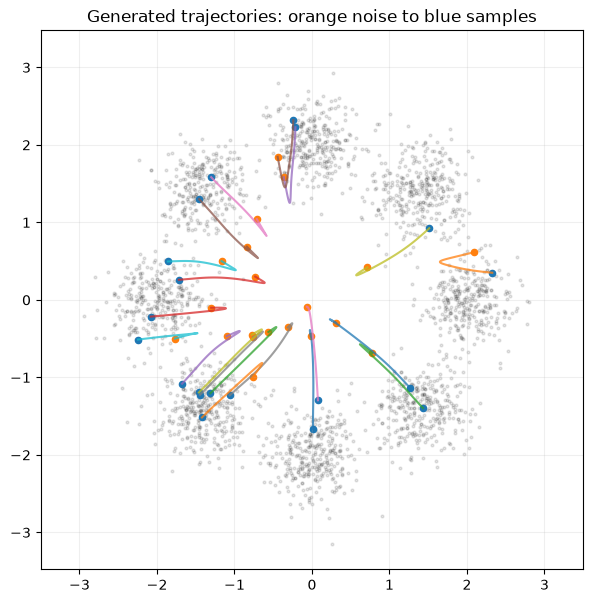

In [ ]:
trajectory_steps = 50
_, all_snapshots = sample_rectified_flow(
    flow_model,
    initial_noise[:20],
    trajectory_steps,
    snapshot_indices=tuple(range(1, trajectory_steps + 1)),
)

# stack snapshot tensors into shape (number_times, 20, 2).
trajectories = torch.stack([all_snapshots[step] for step in range(trajectory_steps + 1)], dim=0)
assert trajectories.shape == (trajectory_steps + 1, 20, 2)

plt.figure(figsize=(7, 7))
plt.scatter(*sample_real_data(2500).T, s=4, alpha=0.1, color="black")
for sample_index in range(trajectories.shape[1]):
    path = trajectories[:, sample_index]
    plt.plot(path[:, 0], path[:, 1], alpha=0.75)
    plt.scatter(*path[0], s=20, color="tab:orange")
    plt.scatter(*path[-1], s=20, color="tab:blue")
plt.axis("equal")
plt.xlim(-3.5, 3.5)
plt.ylim(-3.5, 3.5)
plt.title("Generated trajectories: orange noise to blue samples")
plt.grid(alpha=0.2)
plt.show()

## 10. Diffusion and rectified flow: the shared picture

Both approaches learn a time-dependent transformation between a simple noise distribution and the data distribution, but the training targets and sampling equations differ.

| Question | Diffusion noise prediction | Rectified flow in this notebook |
| --- | --- | --- |
| How are intermediate states made? | A scheduled mixture of clean data and Gaussian noise | Linear interpolation between independently sampled noise and data |
| What does the network predict? | Often added noise, though other parameterizations exist | A velocity vector |
| How are samples generated? | Repeated reverse scheduler updates | Numerical integration of a learned velocity field |
| Why provide time? | The meaning and noise level of the input change with the step | The useful direction changes along the path |

Modern systems may use alternative prediction targets, stochastic or deterministic samplers, latent-space models, conditioning, guidance, and Transformer backbones. Those choices refine the same broad idea rather than changing the basic noise-to-data viewpoint.

## Reflection

Answer briefly after completing and running the notebook.

1. What happens to the data contribution and noise contribution as $\bar{\alpha}_t$ decreases?

   **Answer:** As $\bar{\alpha}_t$ decreases, the clean-data coefficient $\sqrt{\bar{\alpha}_t}$ decreases, while the noise coefficient $\sqrt{1-\bar{\alpha}_t}$ increases. The sample therefore contains less data structure and more noise.

2. Why must a diffusion or flow model receive time in addition to the current sample?

   **Answer:** Time tells the model which stage of the transformation it is processing. The same position may require a different noise estimate or velocity near $t=0$ than near $t=1$.

3. In rectified-flow training, where do the target velocities come from even though the dataset contains no velocity labels?

   **Answer:** from noise to data interpolation 

4. Why can generated trajectories curve even though the artificial training paths are straight?

   **Answer:** The model does not remember individual straight training pairs. It learns an average velocity from many pairs, and that velocity is recalculated at every new position and time. Its direction can consequently change along a generated trajectory, producing a curve.

5. What does increasing the number of Euler steps improve, and what can it not fix?

   **Answer:** More Euler steps reduce numerical integration error by following the learned velocity field with smaller movements. They cannot fix an inaccurate or poorly trained velocity field.

6. How does rectified-flow generation differ from GAN generation?

   **Answer:** rectified flow predicts velocity from noise to data point at time t. GAN has nothing similar to that - it learns to represent data distribution in latent space through feedback from real or fake image classification. Rectified flow starts from noise and performs many time-dependent velocity updates. A GAN generator maps a latent vector to a generated sample in one forward pass and learns from discriminator feedback rather than explicit velocity targets.

7. Why are nearest-mode distance and coverage useful here but unsuitable as general image-generation metrics?

   **Answer:** The synthetic distribution provides eight known centers, making coverage and nearest-center distance meaningful. Real images have high-dimensional structure and no small collection of exact mode centers, so these metrics would not reliably measure image quality or semantics.

8. State the central noise-to-data idea shared by diffusion and rectified flow in your own words.

   **Answer:** predict most probable transition step from noise to data at specific time t. Both methods learn a time-dependent transformation that turns samples from a simple noise distribution into samples resembling the data distribution. Diffusion commonly predicts noise for reverse updates, whereas rectified flow predicts movement directions.